In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score
from xgboost import XGBClassifier
import joblib  # For saving models
import time  # For measuring computational time

# Load the dataset
data = pd.read_csv("Synthetic Frailty Data.csv")  # Replace with your dataset's file path
data.head()

# Preprocess the data
label_encoder = LabelEncoder()

# Map 'Time Up and Go Result' to numeric values
data['Time Up and Go Result'] = label_encoder.fit_transform(data['Time Up and Go Result'])

# Define input features (X) and output target (y)
X = data[['Time Up and Go Test (s)']]  # Using 'Time Up and Go Test (s)' as the input feature
y = data['Time Up and Go Result']  # The target is 'Time Up and Go Result'

# Standardize features for models like SVM and KNN
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Save the scaler and label encoder
joblib.dump(scaler, 'Scaler_TUG.pkl')
print("Scaler saved as 'Scaler_TUG.pkl'")
joblib.dump(label_encoder, 'Label_Encoder_TUG.pkl')  # Save the LabelEncoder
print("Label Encoder saved as 'Label_Encoder_TUG.pkl'")

# Initialize models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Support Vector Machine": SVC(random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "XGBoost": XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
}

# Train and evaluate models
results = {}
computation_costs = {}

for model_name, model in models.items():
    start_time = time.time()  # Start timing
    model.fit(X_train, y_train)
    end_time = time.time()  # End timing

    # Predictions
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    # Computational cost (training time in seconds)
    training_time = end_time - start_time
    computation_costs[model_name] = training_time

    # Print model results
    print(f"Model: {model_name}")
    print(f"Accuracy: {acc:.2f}")
    print(f"Training Time (seconds): {training_time:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=[str(cls) for cls in label_encoder.classes_]))

    print("-" * 50)
    results[model_name] = acc

    # Save the model as a .pkl file with _TUG suffix
    file_name = f"{model_name.replace(' ', '_')}_TUG.pkl"  # Append _TUG to the file name
    joblib.dump(model, file_name)
    print(f"Model '{model_name}' saved as '{file_name}'")

# Compare accuracies and computational costs
print("\nModel Performance Summary:")
for model_name, acc in results.items():
    print(f"{model_name}: Accuracy = {acc:.2f}, Training Time = {computation_costs[model_name]:.4f} seconds")


Scaler saved as 'Scaler_TUG.pkl'
Label Encoder saved as 'Label_Encoder_TUG.pkl'
Model: Logistic Regression
Accuracy: 0.90
Training Time (seconds): 0.3435

Classification Report:
                            precision    recall  f1-score   support

       Assistance Required       1.00      0.93      0.97        30
Musculoskeletal Disability       1.00      0.27      0.42        26
                    Normal       0.89      1.00      0.94        41
              Risk of Fall       0.87      1.00      0.93       103

                  accuracy                           0.90       200
                 macro avg       0.94      0.80      0.82       200
              weighted avg       0.91      0.90      0.87       200

--------------------------------------------------
Model 'Logistic Regression' saved as 'Logistic_Regression_TUG.pkl'
Model: Random Forest
Accuracy: 1.00
Training Time (seconds): 0.6698

Classification Report:
                            precision    recall  f1-score   suppo

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:183: UserWarning: [05:31:58] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Model: XGBoost
Accuracy: 0.99
Training Time (seconds): 0.5276

Classification Report:
                            precision    recall  f1-score   support

       Assistance Required       1.00      1.00      1.00        30
Musculoskeletal Disability       1.00      0.96      0.98        26
                    Normal       0.98      1.00      0.99        41
              Risk of Fall       1.00      1.00      1.00       103

                  accuracy                           0.99       200
                 macro avg       0.99      0.99      0.99       200
              weighted avg       1.00      0.99      0.99       200

--------------------------------------------------
Model 'XGBoost' saved as 'XGBoost_TUG.pkl'

Model Performance Summary:
Logistic Regression: Accuracy = 0.90, Training Time = 0.3435 seconds
Random Forest: Accuracy = 1.00, Training Time = 0.6698 seconds
Support Vector Machine: Accuracy = 0.98, Training Time = 0.0241 seconds
K-Nearest Neighbors: Accuracy = 0.98, Tra

In [ ]:
import zipfile
# Create a zip archive containing the models, scaler, and label encoder
files_to_download = [
    "Logistic_Regression_TUG.pkl", "Random_Forest_TUG.pkl", "Support_Vector_Machine_TUG.pkl",
    "K-Nearest_Neighbors_TUG.pkl", "XGBoost_TUG.pkl", "Scaler_TUG.pkl", "Label_Encoder_TUG.pkl"
]
with zipfile.ZipFile('TUG_Models.zip', 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file in files_to_download:
        zipf.write(file)

print("Download the 'TUG_Models.zip' file from your directory.")

Download the 'TUG_Models.zip' file from your directory.


Model: Logistic Regression
Accuracy: 0.90
Training Time: 0.0890 seconds
                            precision    recall  f1-score   support

       Assistance Required       1.00      0.93      0.97        30
Musculoskeletal Disability       1.00      0.27      0.42        26
                    Normal       0.89      1.00      0.94        41
              Risk of Fall       0.87      1.00      0.93       103

                  accuracy                           0.90       200
                 macro avg       0.94      0.80      0.82       200
              weighted avg       0.91      0.90      0.87       200

Model saved as 'Logistic_Regression_TUG.pkl'
ROC AUC: 0.9998


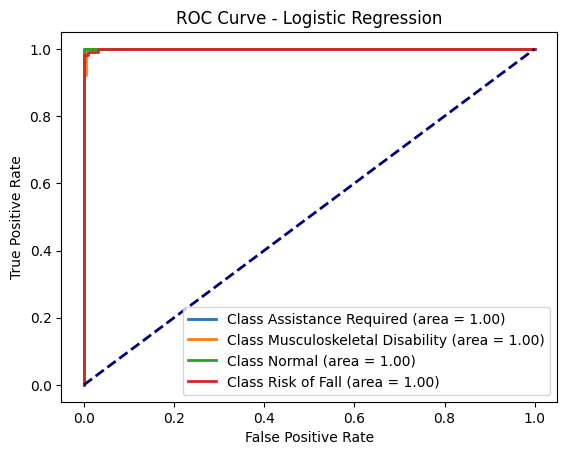

Model: Random Forest
Accuracy: 1.00
Training Time: 0.3515 seconds
                            precision    recall  f1-score   support

       Assistance Required       1.00      1.00      1.00        30
Musculoskeletal Disability       1.00      1.00      1.00        26
                    Normal       1.00      1.00      1.00        41
              Risk of Fall       1.00      1.00      1.00       103

                  accuracy                           1.00       200
                 macro avg       1.00      1.00      1.00       200
              weighted avg       1.00      1.00      1.00       200

Model saved as 'Random_Forest_TUG.pkl'
ROC AUC: 1.0000


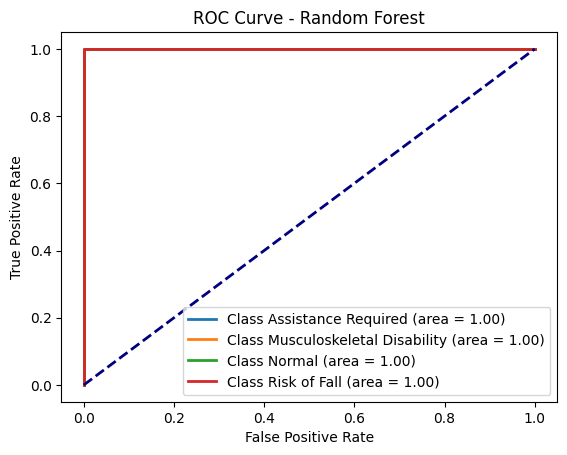

Model: Support Vector Machine
Accuracy: 0.98
Training Time: 0.0645 seconds
                            precision    recall  f1-score   support

       Assistance Required       1.00      1.00      1.00        30
Musculoskeletal Disability       0.96      0.92      0.94        26
                    Normal       1.00      0.98      0.99        41
              Risk of Fall       0.98      1.00      0.99       103

                  accuracy                           0.98       200
                 macro avg       0.99      0.97      0.98       200
              weighted avg       0.98      0.98      0.98       200

Model saved as 'Support_Vector_Machine_TUG.pkl'
ROC AUC: 0.9999


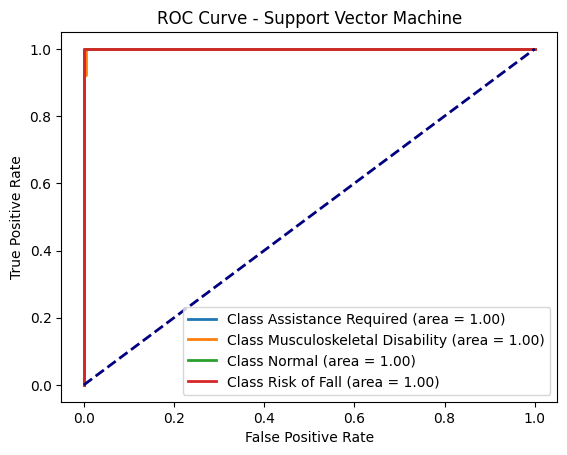

Model: K-Nearest Neighbors
Accuracy: 0.98
Training Time: 0.0025 seconds
                            precision    recall  f1-score   support

       Assistance Required       1.00      0.93      0.97        30
Musculoskeletal Disability       0.96      0.96      0.96        26
                    Normal       1.00      0.98      0.99        41
              Risk of Fall       0.97      1.00      0.99       103

                  accuracy                           0.98       200
                 macro avg       0.98      0.97      0.98       200
              weighted avg       0.98      0.98      0.98       200

Model saved as 'K-Nearest_Neighbors_TUG.pkl'
ROC AUC: 0.9999


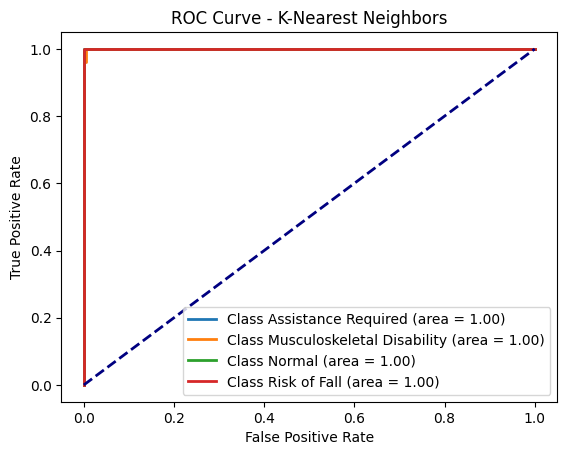

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:183: UserWarning: [05:32:01] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Model: XGBoost
Accuracy: 0.99
Training Time: 0.6523 seconds
                            precision    recall  f1-score   support

       Assistance Required       1.00      1.00      1.00        30
Musculoskeletal Disability       1.00      0.96      0.98        26
                    Normal       0.98      1.00      0.99        41
              Risk of Fall       1.00      1.00      1.00       103

                  accuracy                           0.99       200
                 macro avg       0.99      0.99      0.99       200
              weighted avg       1.00      0.99      0.99       200

Model saved as 'XGBoost_TUG.pkl'
ROC AUC: 0.9980


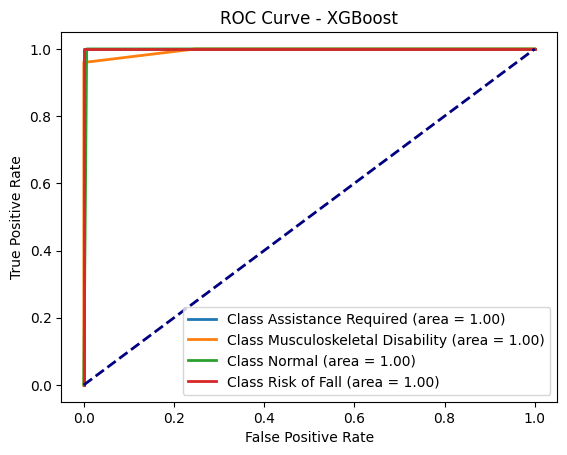


Model Performance Summary:
Logistic Regression: Accuracy = 0.90, Training Time = 0.0890 seconds
Random Forest: Accuracy = 1.00, Training Time = 0.3515 seconds
Support Vector Machine: Accuracy = 0.98, Training Time = 0.0645 seconds
K-Nearest Neighbors: Accuracy = 0.98, Training Time = 0.0025 seconds
XGBoost: Accuracy = 0.99, Training Time = 0.6523 seconds


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
from xgboost import XGBClassifier
import joblib
import time
import matplotlib.pyplot as plt
import numpy as np

# Load the dataset
data = pd.read_csv("Synthetic Frailty Data.csv")
data.head()

# Preprocess the data
label_encoder = LabelEncoder()
data['Time Up and Go Result'] = label_encoder.fit_transform(data['Time Up and Go Result'])

# Input features and target
X = data[['Time Up and Go Test (s)']]
y = data['Time Up and Go Result']

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Save scaler and label encoder
joblib.dump(scaler, 'Scaler_TUG.pkl')
joblib.dump(label_encoder, 'Label_Encoder_TUG.pkl')

# Initialize models (SVC needs probability=True for ROC)
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Support Vector Machine": SVC(probability=True, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "XGBoost": XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
}

results = {}
computation_costs = {}

# Binarize labels for ROC AUC if multiclass
y_test_bin = label_binarize(y_test, classes=range(len(label_encoder.classes_)))

for model_name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time()

    # Predictions
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results[model_name] = acc
    computation_costs[model_name] = end_time - start_time

    print(f"Model: {model_name}")
    print(f"Accuracy: {acc:.2f}")
    print(f"Training Time: {computation_costs[model_name]:.4f} seconds")
    print(classification_report(y_test, y_pred, target_names=[str(cls) for cls in label_encoder.classes_]))

    # Save model
    file_name = f"{model_name.replace(' ', '_')}_TUG.pkl"
    joblib.dump(model, file_name)
    print(f"Model saved as '{file_name}'")

    # ROC AUC
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)
    else:
        # For models like KNN with no predict_proba, use decision_function if available
        try:
            y_prob = model.decision_function(X_test)
            y_prob = np.exp(y_prob) / np.sum(np.exp(y_prob), axis=1, keepdims=True)  # Softmax
        except:
            y_prob = None

    if y_prob is not None:
        # Multiclass ROC AUC
        if y_prob.shape[1] > 2:
            roc_auc = roc_auc_score(y_test_bin, y_prob, multi_class='ovr')
        else:
            roc_auc = roc_auc_score(y_test_bin, y_prob[:,1])

        print(f"ROC AUC: {roc_auc:.4f}")

        # Plot ROC curve
        plt.figure()
        if y_prob.shape[1] > 2:
            # Plot one-vs-rest ROC for each class
            for i, cls in enumerate(label_encoder.classes_):
                fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
                plt.plot(fpr, tpr, lw=2, label=f'Class {cls} (area = {auc(fpr, tpr):.2f})')
        else:
            fpr, tpr, _ = roc_curve(y_test_bin, y_prob[:,1])
            plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')

        plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f'ROC Curve - {model_name}')
        plt.legend(loc="lower right")
        plt.show()

print("\nModel Performance Summary:")
for model_name, acc in results.items():
    print(f"{model_name}: Accuracy = {acc:.2f}, Training Time = {computation_costs[model_name]:.4f} seconds")


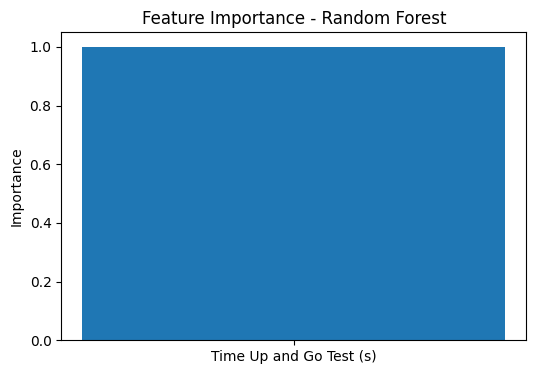

In [4]:
# Get the trained Random Forest model
rf_model = models["Random Forest"]  # Use the same key you used in your dictionary

# Get feature importances
feature_importances = rf_model.feature_importances_
features = X.columns

# Create a DataFrame and sort by importance
df_importance = pd.DataFrame({'Feature': features, 'Importance': feature_importances})
df_importance.sort_values(by='Importance', ascending=False, inplace=True)

# Plot
plt.figure(figsize=(6,4))
plt.bar(df_importance['Feature'], df_importance['Importance'])
plt.title('Feature Importance - Random Forest')
plt.ylabel('Importance')
plt.show()
